# 03. Sensor models and the coverage matrix

This notebook covers the second half of **phase 2**: from the optical depth $\tau$ of notebook 02 to a
**detection probability**, for a camera and for a radar, then the sparse matrix that feeds every
optimisation.

$$
P_\text{det}(x) = T(x) \times P_\text{sensor}(\text{distance, angles}),
\qquad
T = \begin{cases} e^{-\alpha_c \tau} & \text{camera (light travels one way)} \\
e^{-2 \alpha_r \tau} & \text{radar (on the power, there and back)} \end{cases}
$$

| | Camera | Radar |
|---|---|---|
| Criterion | pixel density on the target | signal-to-noise ratio |
| Detection law | TTPF (Johnson criteria) on $x = \text{ppm} / 25$ px/m | Swerling I: $P_d = P_{fa}^{1/(1+\text{SNR})}$ |
| Field | exact pinhole, 8 azimuths | 360°, ±15° beam, tilt 0 / 5 / 10 / 15° |
| Vegetation | $\alpha_c = 1$ (geometric optics) | $\alpha_r = 0.3$ (assumption) |

In [9]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import src.analysis, src.intruder_evaluation, src.nsga_analysis, src.pareto  # noqa: F401  (they select the Agg backend)
from src.site import load_config

%matplotlib inline

cfg = load_config()
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True})
pd.set_option("display.width", 160)

## 1. Camera: pixel density and the TTPF

A camera with $N_h$ horizontal pixels and a horizontal field of view $\text{HFOV}$ puts, on a target at
depth $z$ along its optical axis,

$$
\text{ppm}(z) = \frac{N_h}{2 z \tan(\text{HFOV}/2)} \quad \text{pixels per metre.}
$$

EN 62676-4 sets the **detection** threshold of a person at 25 px/m (DORI criteria). The standard gives a
threshold, not a probability; the shape of the curve comes from the **Target Transfer Probability
Function** of the Johnson criteria:

$$
P(x) = \frac{x^E}{1 + x^E}, \qquad E = 2.7 + 0.7x, \qquad x = \frac{\text{ppm}}{25},
$$

so $P = 0.5$ at the threshold, 0.94 at twice the density and 0.11 at half of it. The distance where
$\text{ppm} = 25$ is the design range $r_\text{design}$ of the lens.

In [10]:
from src.sensors import Camera, Radar, load_sensors, swerling1, ttpf

cams, radars, azimuths, tilts = load_sensors(cfg)
pd.DataFrame([dict(name=c.name, hfov_deg=c.hfov_deg, vfov_deg=round(c.vfov_deg, 1),
                   r_design_m=round(c.r_design, 1), cost=c.cost) for c in cams])

,name,hfov_deg,vfov_deg,r_design_m,cost
0,cam_wide,90,58.7,38.4,1.0
1,cam_standard,60,36.0,66.5,1.0
2,cam_tele,30,17.1,143.3,1.3


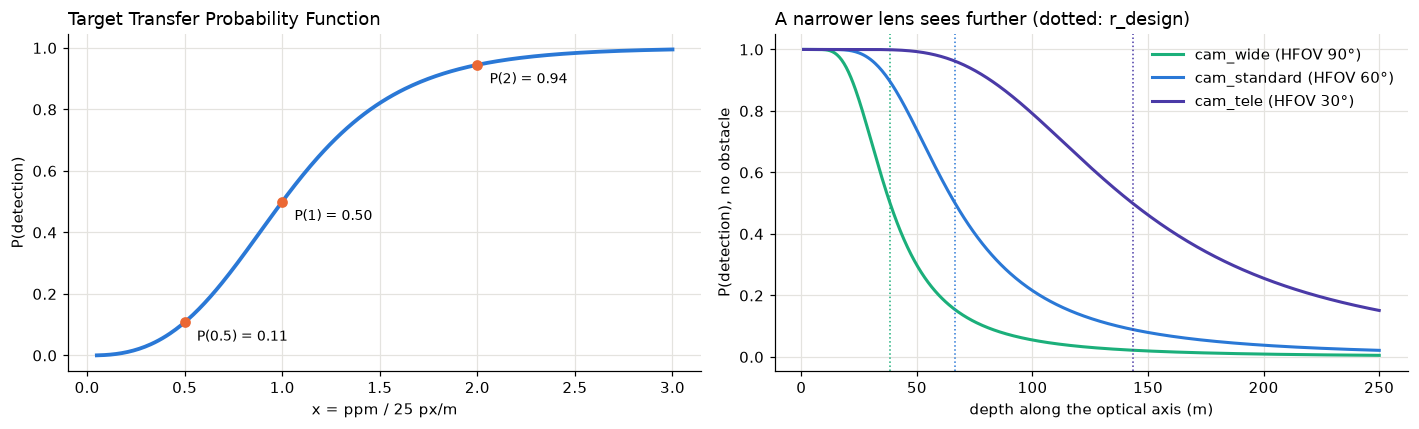

In [11]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
x = np.linspace(0.05, 3, 300)
a1.plot(x, ttpf(x), color="#2a78d6", lw=2.5)
for xv in (0.5, 1, 2):
    a1.plot(xv, ttpf(xv), "o", color="#eb6834")
    a1.annotate(f"P({xv:g}) = {float(ttpf(xv)):.2f}", (xv, float(ttpf(xv))), xytext=(8, -12),
                textcoords="offset points", fontsize=9)
a1.set_xlabel("x = ppm / 25 px/m"); a1.set_ylabel("P(detection)")
a1.set_title("Target Transfer Probability Function", loc="left")

z = np.linspace(1, 250, 500)
for cam, col in zip(cams, ("#1baf7a", "#2a78d6", "#4a3aa7")):
    p = ttpf(cam.n_h / (2 * z * np.tan(np.radians(cam.hfov_deg / 2))) / cam.ppm_50)
    a2.plot(z, p, color=col, lw=2, label=f"{cam.name} (HFOV {cam.hfov_deg:g}°)")
    a2.axvline(cam.r_design, color=col, ls=":", lw=1)
a2.set_xlabel("depth along the optical axis (m)"); a2.set_ylabel("P(detection), no obstacle")
a2.set_title("A narrower lens sees further (dotted: r_design)", loc="left")
a2.legend(frameon=False)
plt.tight_layout(); plt.show()

### Exact pinhole geometry

The installer tilts the camera so that the top edge of the image hits the ground at $r_\text{design}$:
$\text{tilt} = \arctan(h / r_\text{design}) + \text{VFOV}/2$. Only the azimuth stays a decision variable.
Each cell is then projected into the camera frame; it is in the field if its image coordinates are within
the half-angles, and its density uses its depth along the axis. The footprint of a tilted camera is a
**trapezium**, not a circular sector. On a flat, obstacle-free plane, a camera 6 m high looking north:

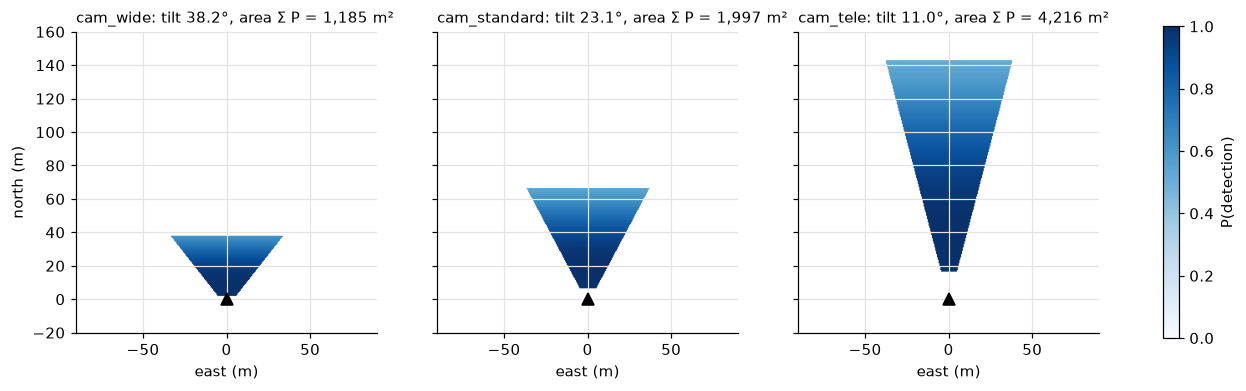

In [12]:
from src.sensors import Geometry, p_camera

res = 0.5
yy, xx = np.mgrid[160:-20:-res, -90:90:res]           # north up, metres around the mast
geo = Geometry(dx=xx, dy=yy, dz=np.full(xx.shape, 6.0), h_rel=6.0)   # target 6 m below the sensor
no_obstacle = np.zeros(xx.shape)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
for ax, cam in zip(axes, cams):
    p = p_camera(no_obstacle, geo, cam, 0.0)
    im = ax.imshow(np.where(p > 0, p, np.nan), extent=(-90, 90, -20, 160), cmap="Blues", vmin=0, vmax=1)
    ax.plot(0, 0, "k^", ms=8)
    ax.set_title(f"{cam.name}: tilt {cam.tilt_deg(6.0):.1f}°, "
                 f"area Σ P = {p.sum() * res ** 2:,.0f} m²", loc="left", fontsize=10)
    ax.set_xlabel("east (m)")
axes[0].set_ylabel("north (m)")
fig.colorbar(im, ax=axes, shrink=0.8, label="P(detection)")
plt.show()

## 2. Radar: radar equation and Swerling I

The radar equation, calibrated on the range $R_{90}$ where the detection probability is 0.9 in free space,
with the two-way vegetation loss:

$$
\text{SNR}(R) = \text{SNR}_{90} \left(\frac{R_{90}}{R}\right)^4 e^{-2\alpha_r \tau},
\qquad
P_d = P_{fa}^{\,1/(1 + \text{SNR})} \ \text{(Swerling I target, single pulse)},
\qquad
\text{SNR}_{90} = \frac{\ln P_{fa}}{\ln 0.9} - 1 .
$$

With $P_{fa} = 10^{-6}$, $\text{SNR}_{90} = 130$ (21.1 dB). The beam covers ±15° around its tilt: a radar
on a mast has a **blind cone** under it, whose size depends on the tilt.

radar_perimeter: R90 = 150 m, P_fa = 1e-06, SNR90 = 130 (21.1 dB), alpha = 0.3


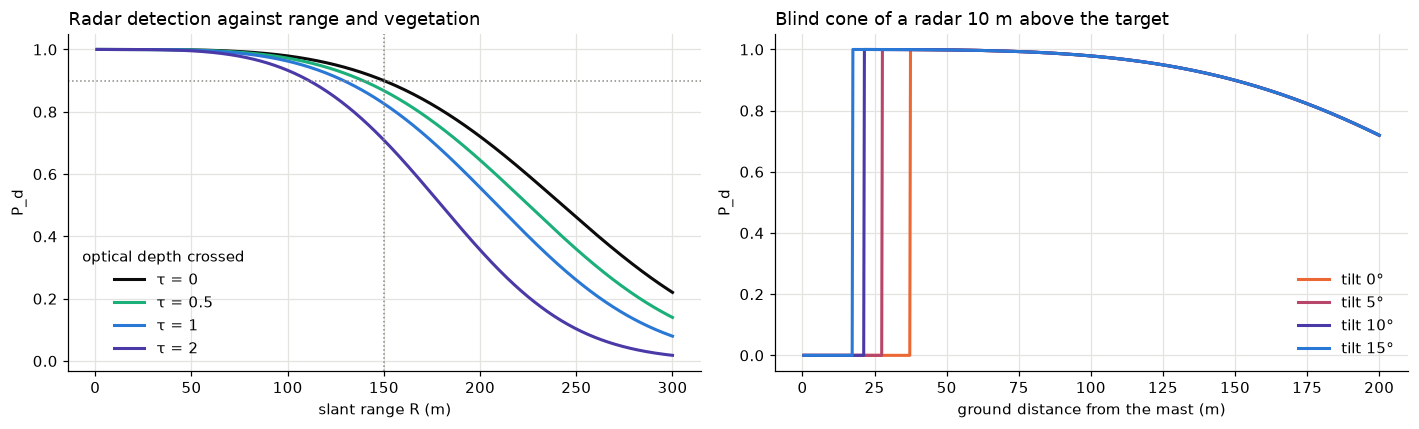

In [13]:
rad = radars[0]
print(f"{rad.name}: R90 = {rad.r90_m:g} m, P_fa = {rad.p_fa:g}, SNR90 = {rad.snr_90:.0f} "
      f"({10 * np.log10(rad.snr_90):.1f} dB), alpha = {rad.alpha}")
R = np.linspace(1, 300, 600)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
for tau, col in zip((0, 0.5, 1, 2), ("#0b0b0b", "#1baf7a", "#2a78d6", "#4a3aa7")):
    snr = rad.snr_90 * (rad.r90_m / R) ** 4 * np.exp(-2 * rad.alpha * tau)
    a1.plot(R, swerling1(snr, rad.p_fa), color=col, lw=2, label=f"τ = {tau:g}")
a1.axhline(0.9, color="#8a8984", ls=":", lw=1); a1.axvline(rad.r90_m, color="#8a8984", ls=":", lw=1)
a1.set_xlabel("slant range R (m)"); a1.set_ylabel("P_d")
a1.set_title("Radar detection against range and vegetation", loc="left")
a1.legend(frameon=False, title="optical depth crossed")

from src.sensors import p_radar
d = np.linspace(0.5, 200, 800)
h = 10.0
for tilt, col in zip((0, 5, 10, 15), ("#eb6834", "#b8456a", "#4a3aa7", "#2a78d6")):
    geo = Geometry(dx=d, dy=np.zeros_like(d), dz=np.full_like(d, h), h_rel=h)
    a2.plot(d, p_radar(np.zeros_like(d), geo, rad, tilt), color=col, lw=2, label=f"tilt {tilt}°")
a2.set_xlabel("ground distance from the mast (m)"); a2.set_ylabel("P_d")
a2.set_title(f"Blind cone of a radar {h:g} m above the target", loc="left")
a2.legend(frameon=False)
plt.tight_layout(); plt.show()

The same optical depth costs a radar twice as much as a camera per unit of $\alpha$ (two-way), but its
$\alpha$ is much smaller: with $\alpha_r = 0.3$, a radar loses $e^{-0.6\tau}$ where a camera loses
$e^{-\tau}$. The sensitivity analysis of week 7 shows that this assumption matters in summer (foliage).

## 3. Detection maps on the site

For one candidate, $\tau$ is computed **once**, then every sensor and every orientation is applied to it.
The roof candidate of notebook 02 at 4 m, with the best azimuth of each camera and the best radar tilt:

C028 (roof) at 4 m


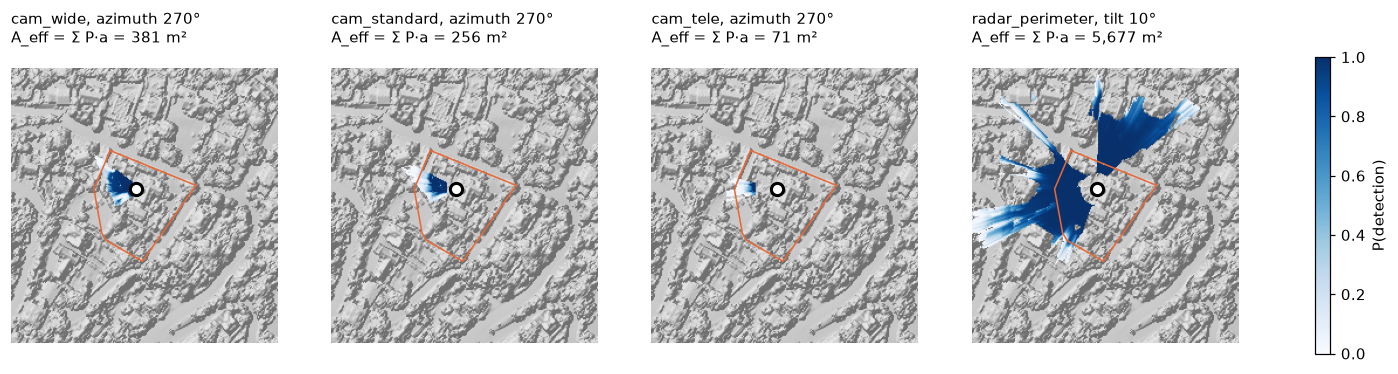

In [14]:
import geopandas as gpd

from src.analysis import hillshade
from src.sensors import geometry
from src.viewshed import compute_tau, prepare_surfaces, read, to_pixel

s = prepare_surfaces(cfg)
g = s.grid
per = gpd.read_file(cfg["site"]["gpkg"], layer="perimeter").geometry.iloc[0]
cand = gpd.read_file(cfg["candidates"]["output"])
c = cand[cand.support == "roof"].iloc[len(cand[cand.support == "roof"]) // 2]
h = 4.0
z_obs = c["z_support"] + h
r0, c0 = to_pixel(g, c.geometry.x, c.geometry.y)
tau = compute_tau(s, c.geometry.x, c.geometry.y, z_obs, cfg)
geo = geometry(s, r0, c0, z_obs)
ground = s.z_opaque < s.z_tgt

maps = []
for cam in cams:
    best = max(azimuths, key=lambda az: np.nansum(np.where(ground, p_camera(tau, geo, cam, az), 0)))
    maps.append((f"{cam.name}, azimuth {best}°", p_camera(tau, geo, cam, best)))
best_tilt = max(tilts, key=lambda tl: np.nansum(np.where(ground, p_radar(tau, geo, rad, tl), 0)))
maps.append((f"{rad.name}, tilt {best_tilt}°", p_radar(tau, geo, rad, best_tilt)))

dsm = read(Path(cfg["rasters"]["out_dir"]) / "dsm.tif")
hs = hillshade(np.nan_to_num(dsm, nan=np.nanmedian(dsm)))
m = 70                                         # zoom: the site + 70 m
b = per.bounds
win = (slice(int((g.ymax - b[3]) - m), int((g.ymax - b[1]) + m)),
       slice(int((b[0] - g.xmin) - m), int((b[2] - g.xmin) + m)))
ext = (g.xmin + win[1].start, g.xmin + win[1].stop, g.ymax - win[0].stop, g.ymax - win[0].start)
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, (title, p) in zip(axes, maps):
    ax.imshow(hs[win], extent=ext, cmap="Greys_r", vmin=-0.8, vmax=1.4)
    im = ax.imshow(np.where(ground & (p > 0.01), p, np.nan)[win], extent=ext, cmap="Blues", vmin=0,
                   vmax=1)
    ax.plot(*per.exterior.xy, color="#eb6834", lw=1)
    ax.plot(c.geometry.x, c.geometry.y, "o", ms=8, mfc="white", mec="k", mew=2)
    a_eff = np.nansum(np.where(ground, p, 0)) * g.res ** 2
    ax.set_title(f"{title}\nA_eff = Σ P·a = {a_eff:,.0f} m²", loc="left", fontsize=10)
    ax.set_axis_off()
fig.colorbar(im, ax=axes, shrink=0.7, label="P(detection)")
print(f"{c['id']} ({c['support']}) at {h:g} m")
plt.show()

The radar dominates: one radar sees more ground than every camera together. Among the cameras, the flat
plane above ranks the tele lens first (its nominal area scales as $\text{HFOV} \times r_\text{design}^2$),
but on the real site the obstacles reverse the ranking: from this roof corner, the long rays of the tele
lens hit the neighbouring roofs and trees, while the wide lens makes the most of its short range. **The best
sensor depends on the location**, and the optimiser must choose them together.

## 4. The coverage matrix

`src.coverage` builds the matrix of the maximal covering problem. A **configuration** $j$ is a choice of
(position, height, sensor, azimuth or tilt); a **cell** $i$ is a ground pixel of a weighted surface, of weight
$w_i$ (notebook 01). The matrix stores $A_{ji} = P_\text{det}$ of configuration $j$ on cell $i$, **sparse**:
values below $p_\text{min} = 0.01$ are set to zero, and the loss this causes is measured.

In [15]:
from scipy import sparse

cov = Path(cfg["coverage"]["out_dir"])
A = sparse.load_npz(cov / "A.npz")
cells = np.load(cov / "cells.npz")
conf = pd.read_csv(cov / "configs.csv")
w = cells["w"]
print(f"A: {A.shape[0]:,} configurations × {A.shape[1]:,} cells, {A.nnz:,} non-zeros "
      f"(density {A.nnz / np.prod(A.shape):.1%}); total weight W = {w.sum():,.0f}")
conf["share"] = (A @ w) / w.sum()           # weighted coverage of each configuration alone
conf.groupby("sensor")["share"].describe(percentiles=[0.5, 0.9])[["count", "50%", "90%", "max"]].round(3)

A: 2,290 configurations × 3,774 cells, 835,222 non-zeros (density 9.7%); total weight W = 15,131


,count,50%,90%,max
sensor,,,,
cam_standard,648.0,0.007,0.051,0.148
cam_tele,394.0,0.002,0.016,0.072
cam_wide,803.0,0.013,0.074,0.180
radar_perimeter,445.0,0.221,0.393,0.507


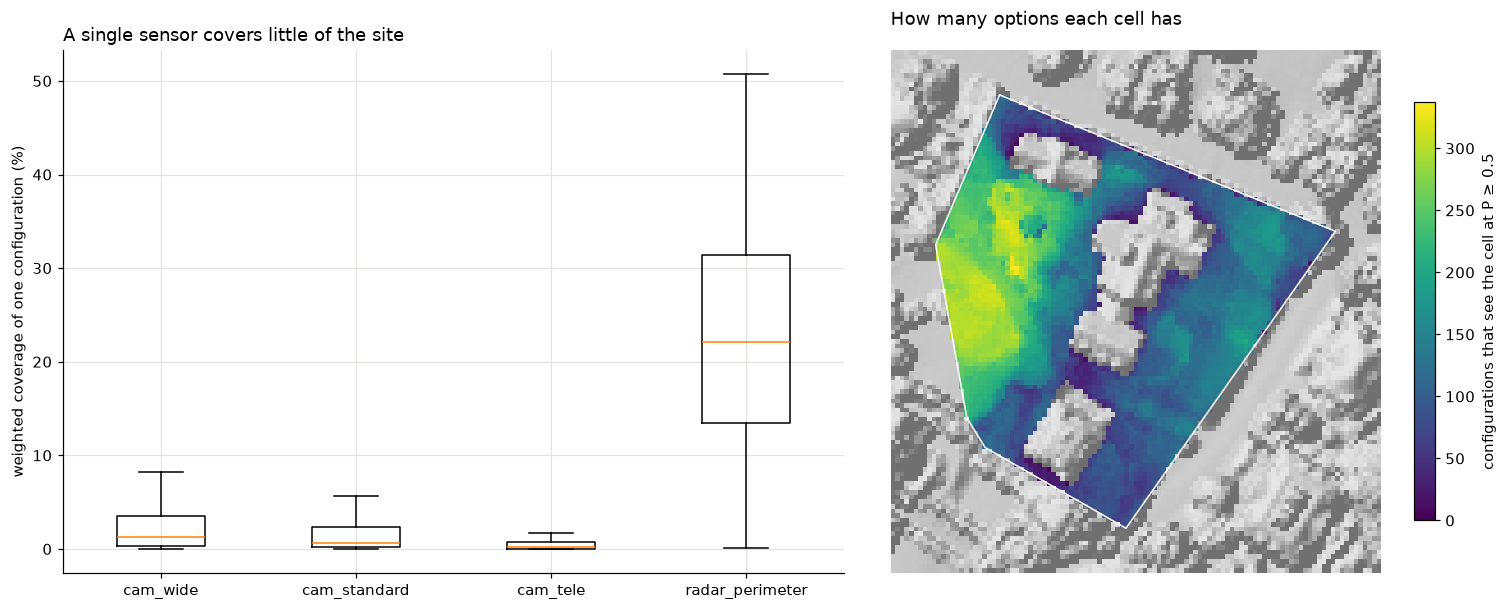

cells never seen at P ≥ 0.5 by any single configuration: 0.0 %


In [16]:
p_max = np.asarray(A.max(axis=0).todense()).ravel()
n_seen = np.asarray((A >= 0.5).sum(axis=0)).ravel()           # configurations with P ≥ 0.5 on the cell
grid_n = np.full(s.z_tgt.shape, np.nan)
grid_n[cells["rows"], cells["cols"]] = n_seen
rr, cc = cells["rows"], cells["cols"]
win = (slice(rr.min() - 10, rr.max() + 11), slice(cc.min() - 10, cc.max() + 11))
sub_ext = (g.xmin + cc.min() - 10, g.xmin + cc.max() + 11, g.ymax - rr.max() - 11, g.ymax - rr.min() + 10)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.2, 1]})
order = ["cam_wide", "cam_standard", "cam_tele", "radar_perimeter"]
a1.boxplot([100 * conf.loc[conf.sensor == n, "share"] for n in order], tick_labels=order, showfliers=False)
a1.set_ylabel("weighted coverage of one configuration (%)")
a1.set_title("A single sensor covers little of the site", loc="left")
a2.imshow(hs[win], extent=sub_ext, cmap="Greys_r", vmin=-0.8, vmax=1.4)
im = a2.imshow(grid_n[win], extent=sub_ext, cmap="viridis")
a2.plot(*per.exterior.xy, color="w", lw=1)
fig.colorbar(im, ax=a2, shrink=0.8, label="configurations that see the cell at P ≥ 0.5")
a2.set_title("How many options each cell has", loc="left"); a2.set_axis_off()
plt.tight_layout(); plt.show()
print(f"cells never seen at P ≥ 0.5 by any single configuration: {100 * (p_max < 0.5).mean():.1f} %")

Even the best radar only covers part of the weight, and the catalog can see almost every cell with at least
one configuration: the problem is a **budget trade-off** between combinations of sensors, not a lack of
positions. This is the input of [04. Coverage optimisation](04_coverage_optimisation.ipynb).